# Fine-tuning de DistilBERT : analyse de sentiment sur des avis de films (IMDB)

**Objectif** : le modèle doit classer des avis de films en *positif* ou *négatif*.
**Ce que vous allez apprendre** : adapter un petit modèle pré-entraîné à une tâche précise, et comparer avant / après.

**Rappel des concepts**
- **LLM** : modèle de langage de grande taille, pré-entraîné sur d'énormes quantités de texte, sans étiquettes.
- **Pré-entraînement** : le modèle apprend la langue en lisant énormément de texte.
- **Fine-tuning** : on adapte ce modèle à une tâche précise avec un petit jeu de données étiquetées.
- **Train / validation / test** : on entraîne sur train, on règle sur validation, on évalue une seule fois sur test (données jamais vues).



## 1. Installation et configuration
On installe les bibliothèques, on fixe la graine aléatoire (résultats reproductibles) et on vérifie que le GPU est actif.

In [ ]:
import time
T0 = time.time()                      # chronomètre du notebook (démarre avant l'installation)

!pip install -q transformers datasets evaluate scikit-learn accelerate

import random, numpy as np, torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("GPU disponible :", torch.cuda.is_available())   # doit afficher True

GPU disponible : True


## 2. Les données
Jeu de données public **IMDB** (avis de films, 0 = négatif, 1 = positif). Il est trop grand pour 15 minutes : on garde un sous-échantillon de 2 000 exemples pour train, 500 pour validation et 500 pour test.

In [ ]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

train_full = dataset["train"].shuffle(seed=SEED).select(range(2500))
test = dataset["test"].shuffle(seed=SEED).select(range(500))

split = train_full.train_test_split(test_size=500, seed=SEED)
train, val = split["train"], split["test"]
print("train :", len(train), "| validation :", len(val), "| test :", len(test))

noms = {0: "négatif", 1: "positif"}
print("Répartition des classes (train) :", {noms[k]: int((np.array(train['label'])==k).sum()) for k in (0,1)})
for i in range(3):
    print(noms[train[i]["label"]], "|", train[i]["text"][:150], "...")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

train : 2000 | validation : 500 | test : 500
Répartition des classes (train) : {'négatif': 995, 'positif': 1005}
positif | I loved the the film. it beautifully analyzes Italian petty bourgeois society, how the leftists of the 70s have given up all their ideals and come to  ...
positif | Ossessione, adapted loosely (or if it is as loose or close to the version I saw of James M. Cain's The Postman Always Rings Twice with Jack Nicholson  ...
négatif | I am terribly sorry, I know that Faßbinder still is called one of the greatest directors in post-war Germany and that most of his films are considered ...


## 3. Point de départ : baseline TF-IDF + régression logistique
Avant de fine-tuner, on mesure un modèle simple (sans LLM) sur le **test**. Ce sera notre point de comparaison.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

vectorizer = TfidfVectorizer(max_features=20000)
X_train = vectorizer.fit_transform(train["text"])
X_test = vectorizer.transform(test["text"])

clf = LogisticRegression(max_iter=1000).fit(X_train, train["label"])
pred = clf.predict(X_test)
base_acc = accuracy_score(test["label"], pred)
base_f1 = f1_score(test["label"], pred)
print("Baseline -> Accuracy :", round(base_acc, 3), "| F1 :", round(base_f1, 3))

Baseline -> Accuracy : 0.806 | F1 : 0.809


## 4. Tokenisation et chargement du modèle
Le modèle ne lit pas des mots mais des **numéros** : le tokenizer découpe le texte en tokens, chaque token a un numéro. Les textes sont tronqués à 128 tokens. On charge ensuite **DistilBERT pré-entraîné** : la tête de classification est nouvelle (le message « newly initialized » est normal, c'est elle qui va apprendre).

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding

MODEL = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL)

phrase = "This movie was absolutely fantastic!"
print(tokenizer.tokenize(phrase))
print(tokenizer(phrase)["input_ids"])

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

train_tok = train.map(tokenize, batched=True)
val_tok = val.map(tokenize, batched=True)
test_tok = test.map(tokenize, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1": f1_score(labels, preds)}

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

['this', 'movie', 'was', 'absolutely', 'fantastic', '!']
[101, 2023, 3185, 2001, 7078, 10392, 999, 102]


NameError: name 'train' is not defined

## 5. Fine-tuning
Hyperparamètres justifiés :
- **2 époques** : le modèle voit 2 fois le jeu d'entraînement (rapide, évite le sur-apprentissage).
- **learning rate 2e-5** : très petit, pour ne pas écraser ce que le modèle a appris au pré-entraînement.
- **batch de 16** : bon compromis mémoire GPU / stabilité.

In [ ]:
from transformers import TrainingArguments, Trainer

args = TrainingArguments(
    output_dir="out",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_tok, eval_dataset=val_tok,
    data_collator=data_collator, compute_metrics=compute_metrics,
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.252788,0.462439,0.826000,0.829746
2,0.163121,0.647049,0.802000,0.820327
3,0.105366,0.613956,0.816000,0.818182


TrainOutput(global_step=375, training_loss=0.17375845591227213, metrics={'train_runtime': 83.1262, 'train_samples_per_second': 72.179, 'train_steps_per_second': 4.511, 'total_flos': 198701097984000.0, 'train_loss': 0.17375845591227213, 'epoch': 3.0})

## 6. Évaluation après fine-tuning
On évalue sur le **test** (jamais vu), puis on affiche la matrice de confusion, la courbe de perte et le tableau avant / après.

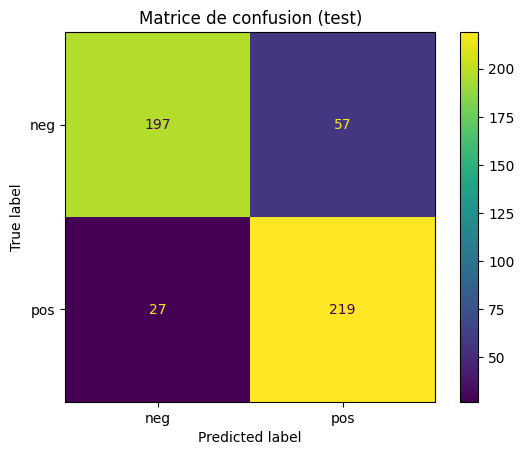

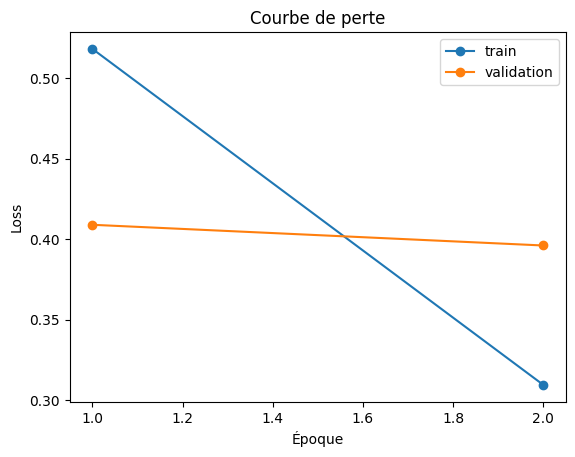

                    Modèle  Accuracy    F1
Baseline (TF-IDF + LogReg)     0.806 0.809
      DistilBERT fine-tuné     0.832 0.839
Temps d'entraînement : 55 s


In [ ]:
import matplotlib.pyplot as plt, pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

out = trainer.predict(test_tok)
preds = np.argmax(out.predictions, axis=-1)
ft_acc = accuracy_score(test["label"], preds)
ft_f1 = f1_score(test["label"], preds)

ConfusionMatrixDisplay(confusion_matrix(test["label"], preds), display_labels=["neg", "pos"]).plot()
plt.title("Matrice de confusion (test)"); plt.show()

logs = trainer.state.log_history
tl = [(l["epoch"], l["loss"]) for l in logs if "loss" in l]
vl = [(l["epoch"], l["eval_loss"]) for l in logs if "eval_loss" in l]
plt.plot(*zip(*tl), marker="o", label="train")
plt.plot(*zip(*vl), marker="o", label="validation")
plt.xlabel("Époque"); plt.ylabel("Loss"); plt.legend(); plt.title("Courbe de perte"); plt.show()

print(pd.DataFrame({
    "Modèle": ["Baseline (TF-IDF + LogReg)", "DistilBERT fine-tuné"],
    "Accuracy": [round(base_acc, 3), round(ft_acc, 3)],
    "F1": [round(base_f1, 3), round(ft_f1, 3)],
}).to_string(index=False))
print("Temps d'entraînement :", round(logs[-1]["train_runtime"]), "s")

## 7. Analyse des erreurs et démo
On regarde 5 avis mal classés (ironie ? avis mixte ? avis long tronqué à 128 tokens ?), puis on teste le modèle sur une phrase écrite par l'utilisateur.
⚠️ La fonction `predire` utilise `trainer.model` (le modèle **entraîné**), pas la variable `model` d'origine.

⏱️ La dernière cellule attend que vous écriviez un avis (en anglais) puis Entrée. Le « temps total » inclut ce temps d'attente.

In [ ]:
labels = np.array(test["label"])
wrong = np.where(preds != labels)[0]
for i in wrong[:5]:
    print("Vrai :", noms[labels[i]], "| Prédit :", noms[preds[i]])
    print(test[int(i)]["text"][:300], "...\n")

def predire(texte):
    m = trainer.model
    m.eval()
    inputs = tokenizer(texte, return_tensors="pt", truncation=True, max_length=128).to(m.device)
    with torch.no_grad():
        logits = m(**inputs).logits
    probs = torch.softmax(logits, dim=-1)[0]
    classe = int(probs.argmax())
    return noms[classe], round(float(probs[classe]), 3)

print(predire("This movie was absolutely fantastic!"))
print(predire("What a waste of time, I hated every minute."))
texte = input("Écris un avis en anglais : ")
print(predire(texte))
print("\nTemps total du notebook :", round((time.time() - T0) / 60, 1), "min")

Vrai : négatif | Prédit : positif
The story is: a turn-of-the-century troupe of actors, along with producers and theatre-owners, have very complicated relationships. A resident playwright has written a psychological drama. He wants to get a good production on stage, but can't unless he convinces a pariticular reviewer to revisit the ...

Vrai : négatif | Prédit : positif
A holiday on a boat, a married couple, an angry waiter and a shipwreck is the reason to this films beginning.<br /><br />I like boobs. No question about that. But when the main character allies with whoever happens to have the most fish at the moment, mostly by having sex with them and playing the r ...

Vrai : négatif | Prédit : positif
Coming from Kiarostami, this art-house visual and sound exposition is a surprise. For a director known for his narratives and keen observation of humans, especially children, this excursion into minimalist cinematography begs for questions: Why did he do it? Was it to keep him busy dur

**Versions des bibliothèques utilisées (voir requirements.txt)**

In [ ]:
   !pip freeze | grep -iE "^(transformers|datasets|scikit-learn|accelerate|torch|numpy|pandas|matplotlib)=="

accelerate==1.15.0
datasets==4.8.5
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
torch==2.14.1+cu130
transformers==5.22.1


### Analyse des erreurs
Dans notre exécution, les 5 avis affichés sont tous **négatifs**, mais le modèle a répondu **positif**. Raisons possibles (à vérifier en lisant chaque avis en entier) :
1. **L'avis commence par raconter l'histoire** (2 avis) : il n'y a presque aucun mot d'opinion au début, donc le modèle n'a rien de négatif à voir.
2. **Éloge avant la critique** : l'auteur écrit d'abord quelque chose de positif, la critique vient après. Le modèle se fie aux premiers mots.
3. **Critique cachée dans des questions** : le sens négatif n'est pas dit directement.
4. **Avis mélangé et long** : on coupe à 128 tokens, donc la partie négative, à la fin, n'est pas lue.

**Ce qu'on retient** : le modèle se trompe quand l'avis résume l'histoire, est ironique, est mélangé ou est long. La matrice de confusion le confirme : il se trompe plus sur les négatifs (57) que sur les positifs (27).

*Si vos avis sont différents des nôtres, adaptez ce texte à ce que vous voyez.*

## 8. À vous de jouer
Dans la cellule d'entraînement (section 5), changez **un seul** paramètre, puis relancez de la section 5 à la section 6 :
1. `num_train_epochs=3` au lieu de 2.
2. `learning_rate=5e-5` au lieu de 2e-5.
3. Dans la section 2, passez à `select(range(4500))` pour avoir plus de données.

Observez l'accuracy, le F1 et le temps d'exécution. Que se passe-t-il ? Notez vos résultats.